# 08 Hypothesis testing and experiment design (BQ8): R version

**BQ8:** Are observed differences between groups real, and how should a future campaign be tested?

Same data, tests and definitions as `08_hypothesis_ab_py.ipynb` (see it for the full explanation). This dataset has no
randomised experiment, so Part A tests observed (non-causal) differences and Part B designs a future A/B test.
Test statistics and p-values must match Python exactly; bootstrap intervals agree only approximately.

## Setup and data

In [1]:
suppressPackageStartupMessages({ library(arrow); library(dplyr); library(tidyr); library(ggplot2); library(scales) })
options(dplyr.summarise.inform = FALSE, scipen = 999, digits = 4, width = 160,
        repr.plot.width = 11, repr.plot.height = 4)
Sys.setenv(TZ = "UTC")

root <- if (dir.exists("data")) "." else ".."
proc <- file.path(root, "data", "processed")
fig  <- file.path(root, "reports", "figures")
dir.create(fig, showWarnings = FALSE, recursive = TRUE)

START <- as.POSIXct("2010-12-01", tz = "UTC"); END <- as.POSIXct("2011-12-01", tz = "UTC")
ALPHA <- 0.05; POWER <- 0.80; N_BOOT <- 2000; SEED <- 42

prod <- read_parquet(file.path(proc, "sales_clean.parquet")) |>
  mutate(date = as.Date(date)) |>
  filter(line_type == "product", invoice_date >= START, invoice_date < END)          # T6
cat(sprintf("Year 2 product lines: %s   invoices: %s\n", comma(nrow(prod)), comma(n_distinct(prod$invoice))))

Year 2 product lines: 497,787   invoices: 18,957


# Part A: Hypothesis tests on observed groups
## A1. Order value: UK vs non-UK customers

In [2]:
orders <- prod |> filter(!cancelled_exact) |> group_by(invoice) |>
  summarise(value = round(sum(revenue), 2), is_uk = first(is_uk)) |> arrange(invoice)   # to the penny
uk <- orders$value[orders$is_uk]; nonuk <- orders$value[!orders$is_uk]

print(data.frame(orders = c(length(uk), length(nonuk)), mean = c(mean(uk), mean(nonuk)),
                 median = c(median(uk), median(nonuk)),
                 geometric_mean = c(exp(mean(log(uk))), exp(mean(log(nonuk)))), row.names = c("UK", "Non-UK")), digits = 6)

t_log <- t.test(log(nonuk), log(uk), var.equal = FALSE)
t_raw <- t.test(nonuk, uk, var.equal = FALSE)
mw <- wilcox.test(nonuk, uk, exact = FALSE, correct = TRUE)
ratio <- exp(mean(log(nonuk)) - mean(log(uk)))
prob_sup <- unname(mw$statistic) / (length(nonuk) * length(uk))
cat(sprintf("\nWelch t-test, log order value: t = %.3f, df = %.1f, p = %.3g   (non-UK typical order = %.2f x UK)\n",
            t_log$statistic, t_log$parameter, t_log$p.value, ratio))
cat(sprintf("Welch t-test, raw order value: t = %.3f, df = %.1f, p = %.3g   (difference in means £%s)\n",
            t_raw$statistic, t_raw$parameter, t_raw$p.value, comma(mean(nonuk) - mean(uk), accuracy = 1)))
cat(sprintf("Mann-Whitney U: U = %s, p = %.3g   (probability a non-UK order is larger than a UK order: %.3f)\n",
            comma(unname(mw$statistic)), mw$p.value, prob_sup))

       orders    mean median geometric_mean
UK      17051 464.462 296.07        244.889
Non-UK   1786 816.792 387.18        392.523

Welch t-test, log order value: t = 16.375, df = 2208.8, p = 5.67e-57   (non-UK typical order = 1.60 x UK)
Welch t-test, raw order value: t = 8.300, df = 1917.7, p = 1.93e-16   (difference in means £352)
Mann-Whitney U: U = 18,697,530, p = 0   (probability a non-UK order is larger than a UK order: 0.614)


                                   estimate ci_low ci_high
Median difference (non-UK - UK), £     91.1   68.8   114.9
Mean difference (non-UK - UK), £      352.3  270.2   437.6


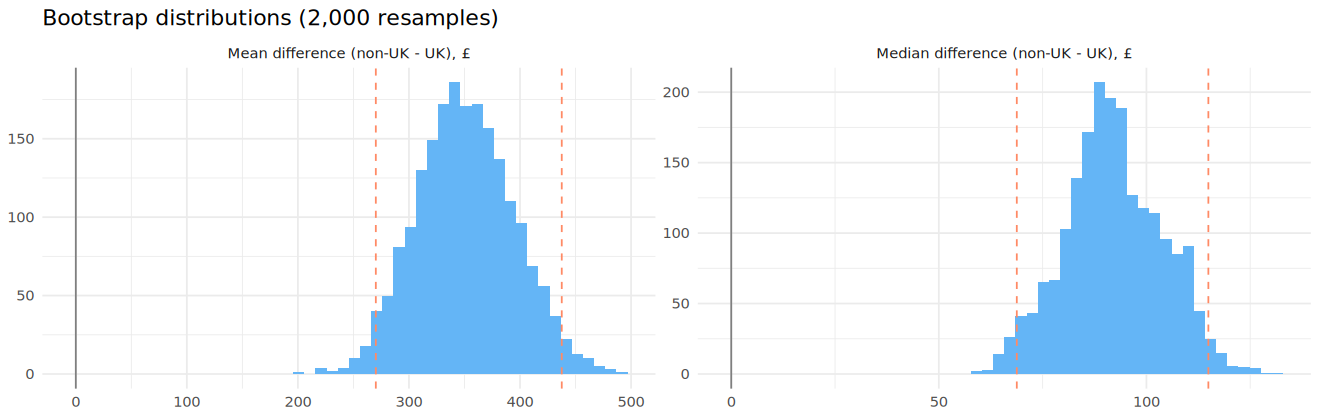

In [3]:
set.seed(SEED)
boot <- t(replicate(N_BOOT, {
  bu <- sample(uk, replace = TRUE); bv <- sample(nonuk, replace = TRUE)
  c(median(bv) - median(bu), mean(bv) - mean(bu))
}))
ci <- data.frame(estimate = c(median(nonuk) - median(uk), mean(nonuk) - mean(uk)),
                 ci_low = apply(boot, 2, quantile, 0.025), ci_high = apply(boot, 2, quantile, 0.975),
                 row.names = c("Median difference (non-UK - UK), £", "Mean difference (non-UK - UK), £"))
print(round(ci, 1))

bd <- data.frame(value = c(boot[, 1], boot[, 2]),
                 stat = rep(c("Median difference (non-UK - UK), £", "Mean difference (non-UK - UK), £"), each = N_BOOT))
lines_df <- data.frame(stat = rownames(ci), lo = ci$ci_low, hi = ci$ci_high)
p_boot <- ggplot(bd, aes(value)) + geom_histogram(bins = 50, fill = "#64B5F6") +
  geom_vline(data = lines_df, aes(xintercept = lo), colour = "#FF8A65", linetype = "dashed") +
  geom_vline(data = lines_df, aes(xintercept = hi), colour = "#FF8A65", linetype = "dashed") +
  geom_vline(xintercept = 0, colour = "grey50") +
  facet_wrap(~stat, scales = "free") + labs(x = NULL, y = NULL, title = "Bootstrap distributions (2,000 resamples)") +
  theme_minimal(base_size = 11)
ggsave(file.path(fig, "bq8_bootstrap_r.png"), p_boot, width = 11, height = 3.5, dpi = 150)
options(repr.plot.width = 11, repr.plot.height = 3.5); p_boot

## A2. Cancellation rate: Q4 (Oct–Dec) vs the rest of the year (two-proportion test)

In [4]:
lc <- prod |> filter(has_customer) |> mutate(q4 = as.integer(format(invoice_date, "%m")) >= 10)
x1 <- sum(lc$cancelled_exact[lc$q4]); n1 <- sum(lc$q4)
x0 <- sum(lc$cancelled_exact[!lc$q4]); n0 <- sum(!lc$q4)
pt <- prop.test(c(x1, x0), c(n1, n0), correct = FALSE)
p1 <- x1 / n1; p0 <- x0 / n0
z <- sign(p1 - p0) * sqrt(unname(pt$statistic))
se <- sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
cat(sprintf("Q4: %s of %s lines cancelled (%.3f%%)   Rest of year: %s of %s (%.3f%%)\n",
            comma(x1), comma(n1), 100 * p1, comma(x0), comma(n0), 100 * p0))
cat(sprintf("Two-proportion z-test: z = %.3f, p = %.3g   chi-square = z² = %.3f\n", z, pt$p.value, pt$statistic))
cat(sprintf("Difference: %+.3f percentage points, 95%% CI [%+.3f, %+.3f]   relative: %+.1f%%\n",
            100 * (p1 - p0), 100 * (p1 - p0 - 1.96 * se), 100 * (p1 - p0 + 1.96 * se), 100 * (p1 / p0 - 1)))

Q4: 838 of 137,118 lines cancelled (0.611%)   Rest of year: 1,939 of 237,071 (0.818%)
Two-proportion z-test: z = -7.100, p = 1.25e-12   chi-square = z² = 50.409
Difference: -0.207 percentage points, 95% CI [-0.262, -0.152]   relative: -25.3%


## A3. Order size and cancellation (chi-square test of independence, Cramér's V)

In [5]:
o <- prod |> group_by(invoice) |> summarise(lines = n(), has_cancel = any(cancelled_exact)) |>
  mutate(size_band = cut(lines, breaks = c(0, 1, 10, 30, Inf), labels = c("1 line", "2-10", "11-30", "31+")))
tab <- table(o$size_band, o$has_cancel)
ch <- chisq.test(tab, correct = FALSE)
cramers_v <- sqrt(unname(ch$statistic) / (sum(tab) * (min(dim(tab)) - 1)))
print(cbind(no_cancel = tab[, "FALSE"], with_cancel = tab[, "TRUE"],
            share_with_cancellation = round(tab[, "TRUE"] / rowSums(tab), 4)))
cat(sprintf("\nChi-square = %.2f, df = %d, p = %.3g   Cramér's V = %.3f\n", ch$statistic, ch$parameter, ch$p.value, cramers_v))

tests <- data.frame(
  comparison = c("Order value, non-UK vs UK", "Order value, non-UK vs UK", "Cancellation rate, Q4 vs rest", "Cancellation vs order size"),
  test = c("Welch t-test (log value)", "Mann-Whitney U", "Two-proportion z-test", "Chi-square test"),
  statistic = c(unname(t_log$statistic), unname(mw$statistic), z, unname(ch$statistic)),
  p_value = c(t_log$p.value, mw$p.value, pt$p.value, ch$p.value))
tests$significant_0.05 <- tests$p_value < ALPHA
tests$significant_bonferroni <- tests$p_value < ALPHA / nrow(tests)
cat("\n"); print(transform(tests, statistic = round(statistic, 4), p_value = format(p_value, digits = 4, scientific = TRUE)))

       no_cancel with_cancel share_with_cancellation
1 line      1387          49                  0.0341
2-10        5365         221                  0.0396
11-30       6958         560                  0.0745
31+         3944         473                  0.1071

Chi-square = 206.52, df = 3, p = 1.64e-44   Cramér's V = 0.104

                     comparison                     test   statistic   p_value significant_0.05 significant_bonferroni
1     Order value, non-UK vs UK Welch t-test (log value)       16.38 5.675e-57             TRUE                   TRUE
2     Order value, non-UK vs UK           Mann-Whitney U 18697530.00 0.000e+00             TRUE                   TRUE
3 Cancellation rate, Q4 vs rest    Two-proportion z-test       -7.10 1.248e-12             TRUE                   TRUE
4    Cancellation vs order size          Chi-square test      206.52 1.644e-44             TRUE                   TRUE


# Part B: Designing an A/B test (win-back email, 90-day reorder rate)

In [6]:
cut_t <- as.POSIXct("2011-09-01", tz = "UTC")
last <- prod |> filter(has_customer, !cancelled_exact, invoice_date < cut_t) |>
  group_by(customer_id) |> summarise(last_buy = max(date))
last$days <- as.numeric(as.Date(cut_t) - last$last_buy)
elig <- last$customer_id[last$days >= 30 & last$days <= 120]
after <- unique(prod$customer_id[prod$has_customer & !prod$cancelled_exact &
                                 prod$invoice_date >= cut_t & prod$invoice_date < cut_t + 90 * 86400])
p0 <- mean(elig %in% after)
cat(sprintf("Eligible customers: %s   baseline 90-day reorder rate p0 = %.1f%%\n", comma(length(elig)), 100 * p0))

z_a <- qnorm(1 - ALPHA / 2); z_b <- qnorm(POWER)
n_per_group <- function(p0, p1) {
  pbar <- (p0 + p1) / 2
  ceiling((z_a * sqrt(2 * pbar * (1 - pbar)) + z_b * sqrt(p0 * (1 - p0) + p1 * (1 - p1)))^2 / (p1 - p0)^2)
}
plan <- data.frame(lift_pp = c(2, 3, 5, 7.5, 10)) |>
  mutate(p_control = p0, p_treatment = p0 + lift_pp / 100,
         n_per_group = mapply(n_per_group, p_control, p_treatment),
         n_total = 2 * n_per_group, share_of_eligible = n_total / length(elig),
         power_prop_test = ceiling(mapply(function(a, b) power.prop.test(p1 = a, p2 = b, sig.level = ALPHA, power = POWER)$n,
                                          p_control, p_treatment)))
print(plan, digits = 4)
cat("(power_prop_test: R's built-in power.prop.test, which uses an exact two-sided power function; it differs by at most a customer or two.)\n")

Eligible customers: 1,408   baseline 90-day reorder rate p0 = 59.2%
  lift_pp p_control p_treatment n_per_group n_total share_of_eligible power_prop_test
1     2.0    0.5916      0.6116        9405   18810           13.3594            9405
2     3.0    0.5916      0.6216        4162    8324            5.9119            4162
3     5.0    0.5916      0.6416        1484    2968            2.1080            1484
4     7.5    0.5916      0.6666         650    1300            0.9233             650
5    10.0    0.5916      0.6916         360     720            0.5114             360
(power_prop_test: R's built-in power.prop.test, which uses an exact two-sided power function; it differs by at most a customer or two.)


Customers per group if all eligible are used: 704
Minimum detectable lift: 7.21 percentage points (59.2% -> 66.4%)

SD of log order value: 1.2031
Orders per group to detect a 5% higher typical order value: 9,546
Orders per group to detect a 10% higher typical order value: 2,502


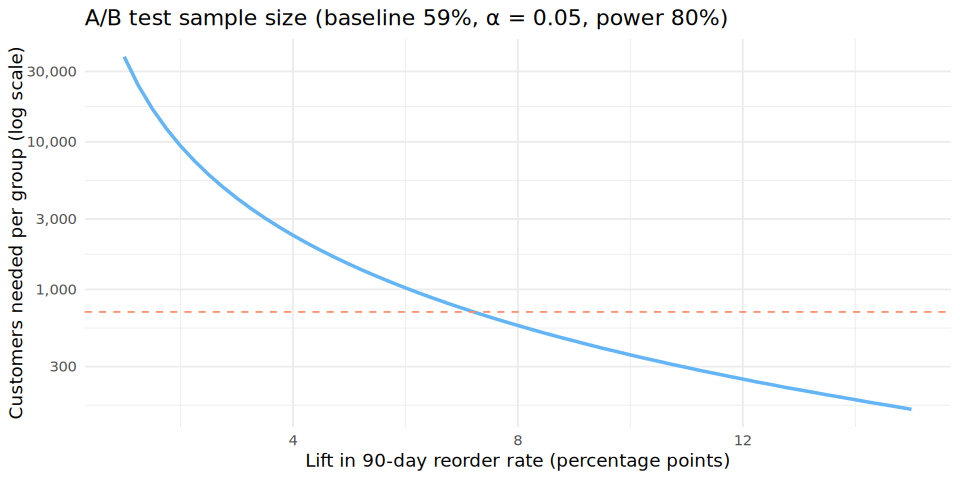

In [7]:
n_avail <- length(elig) %/% 2
lo <- 1e-6; hi <- 1 - p0 - 1e-6
for (i in 1:100) { mid <- (lo + hi) / 2; if (n_per_group(p0, p0 + mid) > n_avail) lo <- mid else hi <- mid }
mde <- hi
cat(sprintf("Customers per group if all eligible are used: %s\n", comma(n_avail)))
cat(sprintf("Minimum detectable lift: %.2f percentage points (%.1f%% -> %.1f%%)\n", 100 * mde, 100 * p0, 100 * (p0 + mde)))

grid <- data.frame(d = seq(0.01, 0.15, length.out = 57)) |> mutate(n = mapply(function(x) n_per_group(p0, p0 + x), d))
p_ss <- ggplot(grid, aes(d * 100, n)) + geom_line(colour = "#64B5F6", linewidth = 1) +
  geom_hline(yintercept = n_avail, colour = "#FF8A65", linetype = "dashed") +
  scale_y_log10(labels = comma) +
  labs(x = "Lift in 90-day reorder rate (percentage points)", y = "Customers needed per group (log scale)",
       title = sprintf("A/B test sample size (baseline %.0f%%, α = 0.05, power 80%%)", 100 * p0)) +
  theme_minimal(base_size = 11)
ggsave(file.path(fig, "bq8_sample_size_r.png"), p_ss, width = 8, height = 4, dpi = 150)

sigma <- sd(log(orders$value))
cat(sprintf("\nSD of log order value: %.4f\n", sigma))
for (lift in c(0.05, 0.10))
  cat(sprintf("Orders per group to detect a %.0f%% higher typical order value: %s\n", 100 * lift,
              comma(ceiling(2 * (z_a + z_b)^2 * sigma^2 / log(1 + lift)^2))))
options(repr.plot.width = 8, repr.plot.height = 4); p_ss

## Checks against Python

In [8]:
dash <- file.path(root, "reports", "dashboard_data")
if (file.exists(file.path(dash, "hypothesis_tests.csv"))) {
  py_t <- read.csv(file.path(dash, "hypothesis_tests.csv"))
  py_p <- read.csv(file.path(dash, "ab_sample_size.csv"))
  py_ci <- read.csv(file.path(dash, "bootstrap_intervals.csv"))
  cat("Test statistics, R vs Python (relative difference):\n")
  print(format(abs(tests$statistic - py_t$statistic) / pmax(abs(py_t$statistic), 1e-12), digits = 3, scientific = TRUE))
  cat(sprintf("p-values identical to 6 decimals (Python CSV precision): %s\n",
            isTRUE(all.equal(round(tests$p_value, 6), py_t$p_value, tolerance = 0))))
  cat(sprintf("Sample sizes identical: %s\n", identical(as.integer(plan$n_per_group), as.integer(py_p$n_per_group))))
  cat("Bootstrap 95% intervals, R vs Python:\n")
  print(data.frame(statistic = rownames(ci), r_low = round(ci$ci_low, 1), py_low = round(py_ci$ci_low, 1),
                   r_high = round(ci$ci_high, 1), py_high = round(py_ci$ci_high, 1)))
} else {
  cat("Run 08_hypothesis_ab_py.ipynb first to create the dashboard CSVs.\n")
}

Test statistics, R vs Python (relative difference):
[1] "9.23e-09" "0.00e+00" "3.36e-08" "9.14e-10"
p-values identical to 6 decimals (Python CSV precision): TRUE
Sample sizes identical: TRUE
Bootstrap 95% intervals, R vs Python:
                           statistic r_low py_low r_high py_high
1 Median difference (non-UK - UK), £  68.8   70.8  114.9   114.5
2   Mean difference (non-UK - UK), £ 270.2  272.6  437.6   437.8
